# Student FULL name: Irbrilyn Kieth Bien
# Student number:48689947

Acknowledgement Statement by students: <br>
Please keep one acknowledgment from the following<br>
	I acknowledge that I have not used GenAI (e. g., ChatGPT) in drafting and proofreading of this assignment.<br>
	I acknowledge that I have only used GenAI (e.g., ChatGPT) in drafting and proofreading this assignment, which is permitted in the assignment instructions. <br>



#  Answer to Section 1 (-2 if not provided) (answer in one cell): 

This exploratory data analysis explores the  Australian lighting suppliers and their products offerings. The dataset includes sales, product types, descriptions, customer locations, and business chains.

The goal is to understand sales patterns across different lighting products, identify outliers, check for skewness in sales data, and gain insights into customer demand.Visualizations such as histograms and bar charts were used, and transformations like log, square root, and Box-Cox were applied to handle skewed data. Outliers were replaced with median values to make the analysis more accurate.

This EDA helps to see which products sell well, identify unusual sales, and provide insights for better inventory and sales decisions.

# Answer to Section 2: EDA (20 Marks) - add as many cell as needed 

In [643]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np 

In [645]:
df = pd.read_excel('Assessment 01.xlsx')
df

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
0,20191025.0,400.0,5.0,Landscape,3.33,Metro Electrical Distributors,MED,COM,Traditional,T612
1,20231013.0,200.0,5.0,Landscape,3.58,Aussie Energy Group,AEG,COM,Traditional,P345
2,20241011.0,200.0,5.0,Landscape,54.5,NextGen Electrical Solutions,NES,OTH,Traditional,P345
3,20191011.0,200.0,5.0,Landscape,26,Metro Electrical Distributors,MED,OTH,Traditional,T504
4,20211021.0,400.0,5.0,Landscape,46.1,Metro Electrical Distributors,MED,COM,Traditional,T504
...,...,...,...,...,...,...,...,...,...,...
1037200,NaN,NaN,NaN,0,1.1,NaN,NaN,NaN,NaN,T431
1037201,NaN,NaN,NaN,0,1.1,NaN,NaN,NaN,NaN,T600
1037202,NaN,NaN,NaN,0,1.1,NaN,NaN,NaN,NaN,T600
1037203,NaN,NaN,NaN,0,1.1,NaN,NaN,NaN,NaN,T215


In [647]:
# find out missing value
df.isna().sum()

sales_date                86077
customer_district_code    86028
item_type                 86028
item_type_description        11
sales                       421
business_chain_l1_name    86028
business_chain_l1_code    86028
business_area_code        86028
light_source              86028
salesperson_code             17
dtype: int64

In [649]:
#in pandas empty cell ' ' are not considered as na, we should convert the empty cells into na to check all the null values
df = df.replace(' ', np.nan)

In [651]:
# check the correct number of null values in the dataset
df.isna().sum()

sales_date                86077
customer_district_code    86028
item_type                 86028
item_type_description        11
sales                       422
business_chain_l1_name    86028
business_chain_l1_code    86028
business_area_code        86028
light_source              86028
salesperson_code             17
dtype: int64

In [653]:
#check the data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037205 entries, 0 to 1037204
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   sales_date              951128 non-null   float64
 1   customer_district_code  951177 non-null   float64
 2   item_type               951177 non-null   float64
 3   item_type_description   1037194 non-null  object 
 4   sales                   1036783 non-null  object 
 5   business_chain_l1_name  951177 non-null   object 
 6   business_chain_l1_code  951177 non-null   object 
 7   business_area_code      951177 non-null   object 
 8   light_source            951177 non-null   object 
 9   salesperson_code        1037188 non-null  object 
dtypes: float64(3), object(7)
memory usage: 79.1+ MB


In [655]:
#sales - should be in numeric(float) format
columns = ['sales']
df[columns] = df[columns].apply(pd.to_numeric, errors='coerce')

In [657]:
# check below the correct data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037205 entries, 0 to 1037204
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   sales_date              951128 non-null   float64
 1   customer_district_code  951177 non-null   float64
 2   item_type               951177 non-null   float64
 3   item_type_description   1037194 non-null  object 
 4   sales                   1036781 non-null  float64
 5   business_chain_l1_name  951177 non-null   object 
 6   business_chain_l1_code  951177 non-null   object 
 7   business_area_code      951177 non-null   object 
 8   light_source            951177 non-null   object 
 9   salesperson_code        1037188 non-null  object 
dtypes: float64(4), object(6)
memory usage: 79.1+ MB


In [659]:
# missing values per row 
row_miss = df[df.isna().any(axis=1)]
row_miss

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
16,20231021.0,300.0,7.0,NaN,5.78,Independent Retailers Association,ZZ2,LMP,Traditional,P342
59,20221019.0,300.0,5.0,NaN,13.10,Metro Electrical Distributors,MED,LMP,Traditional,T203
111,20221009.0,300.0,7.0,NaN,19.90,ProLighting Specialists,ZZ3,LMP,Traditional,P347
192,20191021.0,200.0,7.0,NaN,17.30,Builders Supply Network,ZZ1,LMP,Traditional,P415
236,20201008.0,400.0,7.0,NaN,11.50,Builders Supply Network,ZZ1,LMP,Traditional,P248
...,...,...,...,...,...,...,...,...,...,...
1037200,NaN,NaN,NaN,0,1.10,NaN,NaN,NaN,NaN,T431
1037201,NaN,NaN,NaN,0,1.10,NaN,NaN,NaN,NaN,T600
1037202,NaN,NaN,NaN,0,1.10,NaN,NaN,NaN,NaN,T600
1037203,NaN,NaN,NaN,0,1.10,NaN,NaN,NaN,NaN,T215


In [304]:
## Removing missing values

In [661]:
# missing values per row - as shown above best approach for these records is to drop them since it's more than 50 percent 
df = df[df.isnull().sum(axis=1) < 7]

In [663]:
#As you can see, the rows with 7 null columns have been dropped.
row_miss = df[df.isna().any(axis=1)]
row_miss

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
16,20231021.0,300.0,7.0,NaN,5.78,Independent Retailers Association,ZZ2,LMP,Traditional,P342
59,20221019.0,300.0,5.0,NaN,13.10,Metro Electrical Distributors,MED,LMP,Traditional,T203
111,20221009.0,300.0,7.0,NaN,19.90,ProLighting Specialists,ZZ3,LMP,Traditional,P347
192,20191021.0,200.0,7.0,NaN,17.30,Builders Supply Network,ZZ1,LMP,Traditional,P415
236,20201008.0,400.0,7.0,NaN,11.50,Builders Supply Network,ZZ1,LMP,Traditional,P248
...,...,...,...,...,...,...,...,...,...,...
717533,NaN,300.0,5.0,Landscape,47.50,Metro Electrical Distributors,MED,LMP,Traditional,P342
758206,20171027.0,400.0,8.0,Road-and-street,20.59,NextGen Electrical Solutions,NES,COM,Traditional,NaN
759861,20161002.0,600.0,7.0,Decorative,58.60,ProLighting Specialists,ZZ3,LMP,Traditional,NaN
760224,20181030.0,200.0,1.0,Wall-mount,144.19,NextGen Electrical Solutions,NES,SUR,Traditional,NaN


In [665]:
# check again how many null left in the dataset
df.isna().sum()

sales_date                49
customer_district_code     0
item_type                  0
item_type_description     10
sales                      7
business_chain_l1_name     0
business_chain_l1_code     0
business_area_code         0
light_source               0
salesperson_code          17
dtype: int64

In [309]:
# Imputation

In [667]:
#filter out the values for item_type with item_type 7.0
df_7_0 = df[df['item_type'] == 7.0]
df_7_0

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
9,20221010.0,400.0,7.0,Decorative,2571.07,Metro Electrical Distributors,MED,SUR,Traditional,P342
10,20211026.0,500.0,7.0,Decorative,3.44,Independent Retailers Association,ZZ2,LMP,Traditional,P344
11,20211008.0,200.0,7.0,Decorative,6.30,Nationwide Lighting Group,NLG,LMP,Traditional,T408
12,20211015.0,200.0,7.0,Decorative,6.30,Independent Retailers Association,ZZ2,LMP,Traditional,T408
13,20191007.0,200.0,7.0,Decorative,3.70,Independent Retailers Association,ZZ2,LMP,Traditional,P237
...,...,...,...,...,...,...,...,...,...,...
951149,20161018.0,500.0,7.0,Decorative,174.10,Metro Electrical Distributors,MED,SUR,Traditional,T501
951151,20151013.0,410.0,7.0,Decorative,19.10,Metro Electrical Distributors,MED,SUR,Traditional,T222
951154,20151029.0,200.0,7.0,Decorative,147.35,General Suppliers Pty,ZZZ,LMP,Traditional,T224
951155,20151022.0,200.0,7.0,Decorative,1.10,ProLighting Specialists,ZZ3,LMP,Traditional,P342


In [671]:
# Use a valid variable name and your main dataframe
item_type_7_0_description = df.loc[
    df['item_type'] == 7.0, 'item_type_description'
].dropna().iloc[0]

item_type_7_0_description

'Decorative'

In [673]:
#replace missing values in "item_type_description" where "item_type" is "7.0" with existing item_type_description of 7.0
item_type_7_0_description = 'Decorative'

df.loc[df['item_type'] == 7.0, 'item_type_description'] = df.loc[df['item_type'] == 7.0, 'item_type_description'].fillna(item_type_7_0_description)


In [675]:
# Use a valid variable name and your main dataframe
item_type_5_0_description = df.loc[df['item_type'] == 5.0, 'item_type_description'].dropna().iloc[0]

item_type_5_0_description

'Landscape'

In [677]:
#replace missing values in "item_type_description" where "item_type" is "5.0" with existing item_type_description of 5.0
item_type_5_0_description = 'Landscape'

df.loc[df['item_type'] == 5.0, 'item_type_description'] = df.loc[df['item_type'] == 5.0, 'item_type_description'].fillna(item_type_7_0_description)


In [679]:
#filter rows where  'item_type' is either "7.0" or '5.0"
filtered_item_type = df[df['item_type'].isin([7.0, 5.0])]


print(filtered_item_type)

        sales_date  customer_district_code  item_type item_type_description  \
0       20191025.0                   400.0        5.0             Landscape   
1       20231013.0                   200.0        5.0             Landscape   
2       20241011.0                   200.0        5.0             Landscape   
3       20191011.0                   200.0        5.0             Landscape   
4       20211021.0                   400.0        5.0             Landscape   
...            ...                     ...        ...                   ...   
951169  20171013.0                   500.0        5.0             Landscape   
951171  20151006.0                   500.0        5.0             Landscape   
951172  20151006.0                   200.0        5.0             Landscape   
951175  20151001.0                   500.0        5.0             Landscape   
951176  20171025.0                   500.0        5.0             Landscape   

         sales         business_chain_l1_name busin

In [681]:
row_miss = df[df.isna().any(axis=1)]
row_miss

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
532,20231023.0,400.0,5.0,Landscape,65.22,NextGen Electrical Solutions,NES,COM,Traditional,NaN
550,20211022.0,200.0,5.0,Landscape,102.35,Metro Electrical Distributors,MED,COM,Traditional,NaN
748,20221008.0,200.0,7.0,Decorative,14.00,Builders Supply Network,ZZ1,LMP,Traditional,NaN
823,20211013.0,300.0,7.0,Decorative,11.90,ProLighting Specialists,ZZ3,LMP,Traditional,NaN
1068,20241011.0,300.0,7.0,Decorative,6.26,Builders Supply Network,ZZ1,LMP,Traditional,NaN
...,...,...,...,...,...,...,...,...,...,...
717533,NaN,300.0,5.0,Landscape,47.50,Metro Electrical Distributors,MED,LMP,Traditional,P342
758206,20171027.0,400.0,8.0,Road-and-street,20.59,NextGen Electrical Solutions,NES,COM,Traditional,NaN
759861,20161002.0,600.0,7.0,Decorative,58.60,ProLighting Specialists,ZZ3,LMP,Traditional,NaN
760224,20181030.0,200.0,1.0,Wall-mount,144.19,NextGen Electrical Solutions,NES,SUR,Traditional,NaN


In [683]:
df.isna().sum()

sales_date                49
customer_district_code     0
item_type                  0
item_type_description      0
sales                      7
business_chain_l1_name     0
business_chain_l1_code     0
business_area_code         0
light_source               0
salesperson_code          17
dtype: int64

In [685]:
# Show only rows where sales is null
df[df['sales'].isna()]


,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
610287,20201008.0,300.0,7.0,Decorative,NaN,Independent Retailers Association,ZZ2,LMP,Traditional,T203
610478,20201008.0,300.0,7.0,Decorative,NaN,Independent Retailers Association,ZZ2,LMP,Traditional,T504
610730,20201005.0,400.0,7.0,Decorative,NaN,Independent Retailers Association,ZZ2,LMP,Accessories,T226
610895,20171016.0,710.0,9.0,Garage,NaN,Builders Supply Network,ZZ1,COM,Accessories,P237
611012,20161009.0,200.0,7.0,Decorative,NaN,Unified Electrical Suppliers,UES,LMP,Traditional,T211
611118,20201020.0,300.0,7.0,Decorative,NaN,BrightPower Solutions,BPS,LMP,Traditional,T501
611572,20161016.0,200.0,7.0,Decorative,NaN,Independent Retailers Association,ZZ2,LMP,Traditional,T503


In [687]:
#.reset _index() method is then used to convert this index back intoregular columns, providing a flat dataframe structure
sales_median = df.groupby(['item_type', 'item_type_description'])['sales'].median().reset_index()
sales_median

,item_type,item_type_description,sales
0,1.0,Wall-mount,525.850
1,2.0,Industrial,223.335
2,3.0,Pendants,55.490
3,4.0,Solar,83.900
4,5.0,Decorative,65.220
5,5.0,Landscape,71.100
6,6.0,Healthcare,86.300
7,7.0,Decorative,53.460
8,8.0,Road-and-street,97.040
9,9.0,Garage,105.900


In [689]:
#Get the existing value(first non-null)for a given item_type and item_type_description
decorative_7_sales_median = (sales_median.loc[(sales_median['item_type'] == 7.0) & (sales_median['item_type_description'] == 'Decorative'),'sales'].dropna())


In [691]:
# Step 1: Compute median sales for Decorative 7.0
decorative_7_sales_median = df.loc[
    (df['item_type'] == 7.0) & 
    (df['item_type_description'] == 'Decorative'),
    'sales'
].median()

print("Median for 7.0 Decorative:", decorative_7_sales_median)


Median for 7.0 Decorative: 53.46


In [693]:
# replace the msising values in the sales with the correct values

df.loc[df["item_type"] == 7.0, "sales"] = df.loc[df["item_type"] == 7.0, "sales"].fillna(decorative_7_sales_median)

    

In [697]:
# Show only rows where sales is null
df[df['sales'].isna()]

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code
610895,20171016.0,710.0,9.0,Garage,NaN,Builders Supply Network,ZZ1,COM,Accessories,P237


In [699]:
# Get the existing value (first non-null) for Garage 9.0
garage_9_sales_median = sales_median.loc[
    (sales_median['item_type'] == 9.0) & 
    (sales_median['item_type_description'] == 'Garage'), 
    'sales'
].dropna()

# Step 1: Compute median sales for Garage 9.0
garage_9_sales_median = df.loc[
    (df['item_type'] == 9.0) & 
    (df['item_type_description'] == 'Garage'),
    'sales'
].median()

print("Median for 9.0 Garage:", garage_9_sales_median)

# Step 2: Replace the missing sales values for Garage 9.0 with the median
df.loc[df["item_type"] == 9.0, "sales"] = df.loc[df["item_type"] == 9.0, "sales"].fillna(garage_9_sales_median)


Median for 9.0 Garage: 105.89999999999999


In [701]:
# Show only rows where sales is null
df[df['sales'].isna()]

,sales_date,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,salesperson_code


In [703]:
# Drop rows where 'sales_date' or 'salespersoncode' is NaN since it wont affect the data set
df = df.drop(columns=['sales_date', 'salesperson_code'])


# Check how many NaNs remain in each column
df.isna().sum()


customer_district_code    0
item_type                 0
item_type_description     0
sales                     0
business_chain_l1_name    0
business_chain_l1_code    0
business_area_code        0
light_source              0
dtype: int64

In [ ]:
## unique values in each column

In [707]:
df.shape

(951177, 8)

In [709]:
unique_customer_district_code  = df['customer_district_code'].unique()
print(unique_customer_district_code )

[400. 200. 510. 500. 310. 300. 410. 210. 600. 720. 710. 535. 530. 540.
 520. 545. 100.]


In [711]:
unique_item_type  = df['item_type'].unique()
print(unique_item_type )

[5. 7. 6. 1. 4. 9. 8. 2. 3.]


In [713]:
unique_item_type_description = df['item_type_description'].unique()
print(unique_item_type_description)

['Landscape' 'Decorative' 'Healthcare' 'Wall-mount' 'Solar' 'Garage'
 'Road-and-street' 'Industrial' 'Pendants']


In [715]:
unique_sales = df['sales'].unique()
print(unique_sales)

[3.33000e+00 3.58000e+00 5.45000e+01 ... 1.95971e+04 4.27000e+02
 2.33290e+02]


In [407]:
unique_business_chain_l1_name = df['business_chain_l1_name'].unique()
print(unique_business_chain_l1_name)

['Metro Electrical Distributors' 'Aussie Energy Group'
 'NextGen Electrical Solutions' 'Independent Retailers Association'
 'Nationwide Lighting Group' 'EndUser Solutions' 'ElectraCorp Ltd'
 'ProLighting Specialists' 'BrightPower Solutions' 'General Suppliers Pty'
 'InterGlobal Trading' 'Constructor Supplies' 'Builders Supply Network'
 'Unified Electrical Suppliers' 'Global Electric Wholesalers'
 'Corys Energy Systems' 'Russell & Partners Electric'
 'Ideal Electrical Solutions' 'PowerHub Distribution'
 'Independent Traders Ltd' 'Stewart Electrical Wholesalers'
 'UtilityWorks Group' 'Beacon Lighting Supplies'
 'Active Electric Solutions' 'CetraPro Distributors' 'PowerTools Direct'
 'MitrePro Suppliers' 'Corporate Builders Consortium' 'Inlite NZ Ltd'
 'Russell & Radcliffe Electric' 'DIY Supplies Network' 'Inlite Solutions'
 'CraneCo Distribution' 'HeadOffice Electrical Group' 'Electical Vista'
 'Corporate HQ Solutions' 'ITM Solutions Group' 'CraneCo Old Branch'
 'Independent' 'Export' 'E

In [493]:
# cleaning mispelled in business_chain_l1_name

# Strip extra spaces from both ends
df['business_chain_l1_name'] = df['business_chain_l1_name'].str.strip()

# Apply the replacement
corrections = {'Electical Vista': 'Electrical Vista'}
df['business_chain_l1_name'] = df['business_chain_l1_name'].replace(corrections)

# Verify the change
print(df[df['business_chain_l1_name'].str.contains('Vista')])


        customer_district_code  item_type item_type_description    sales  \
75481                    540.0        6.0            Healthcare   726.10   
199165                   540.0        6.0            Healthcare   601.10   
282391                   540.0        6.0            Healthcare    81.75   
282643                   540.0        6.0            Healthcare    81.75   
282644                   540.0        6.0            Healthcare    81.75   
300329                   540.0        6.0            Healthcare    81.75   
300672                   540.0        6.0            Healthcare    81.75   
300718                   540.0        6.0            Healthcare    81.75   
406496                   540.0        6.0            Healthcare   726.10   
444325                   540.0        6.0            Healthcare  1999.10   
446028                   540.0        6.0            Healthcare  1999.10   
446029                   540.0        6.0            Healthcare  1999.10   
446104      

In [409]:
unique_business_area_code = df['business_area_code'].unique()
print(unique_business_area_code)

['COM                           ' 'OTH                           '
 'SUR                           ' 'LMP                           '
 'PEN                           ' 940 'TRO                           '
 'DLT                           ' 'TAL                           ' 970 999
 980 'FLD                           ' 'URB                           '
 'IAE                           ' 985 'LCP                           '
 'IAI                           ' 920 'SAE                           '
 'EXL                           ' 'HLB                           ' 950
 'RWY                           ' 945 910 960 930]


In [473]:
#cleaning business_area_code (trailing spaces)

#Convert all to string and strip spaces
df['business_area_code'] = df['business_area_code'].astype(str).str.strip()
#Check cleaned unique values
print(df['business_area_code'].unique())




['COM' 'OTH' 'SUR' 'LMP' 'PEN' '940' 'TRO' 'DLT' 'TAL' '970' '999' '980'
 'FLD' 'URB' 'IAE' '985' 'LCP' 'IAI' '920' 'SAE' 'EXL' 'HLB' '950' 'RWY'
 '945' '910' '960' '930']


In [410]:
unique_light_source = df['light_source'].unique()
print(unique_light_source)

['Traditional' '"Traditional"' 'Traditionl' 'Light Emitting Diode' 'LED'
 'Accessories' 'Tradal' 'Tradisional']


In [467]:
# correcting mispelled Traditional

#Strip leading/trailing spaces and remove double quotes
df['light_source'] = df['light_source'].str.strip().str.replace('"', '')

# Correct misspellings of "Traditional"
corrections = {
    'Traditionl': 'Traditional',
    'Tradal': 'Traditional',
    'Tradisional': 'Traditional'
}

df['light_source'] = df['light_source'].replace(corrections)

# Verify unique values
unique_light_source = df['light_source'].unique()
print(unique_light_source)


['Traditional' 'Light Emitting Diode' 'LED' 'Accessories']


Text(0, 0.5, 'Frequency')

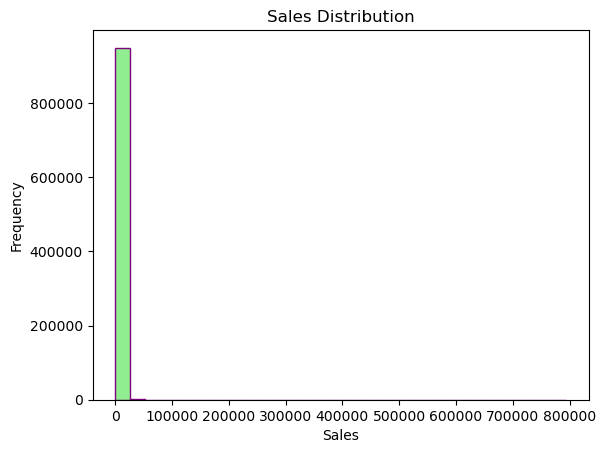

In [737]:
#Histogram of sales

# Histogram of sales
plt.hist(df['sales'], bins=30, color='lightgreen', edgecolor='purple')
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')

In [ ]:
## skewness

In [721]:
# Calculate skewness for sales column
skewness_sales = df['sales'].skew()
print("Skewness of sales:", skewness_sales)


Skewness of sales: 73.71355389417089


In [ ]:
## Calculating skewness before transformation ,skewnessless than -1 or greater than 1 : Indicates a highly skewed distribution

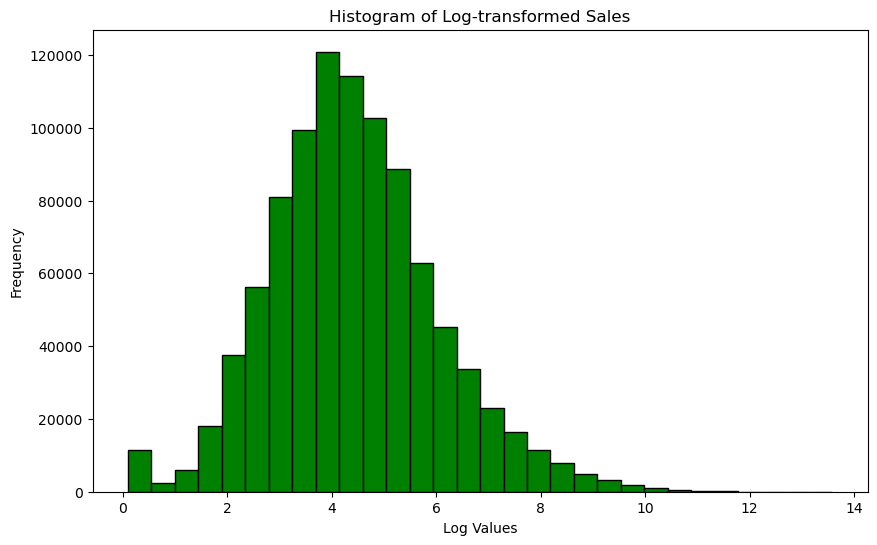

In [735]:
# Applying log transformation to fix skewness in sales
df['sales_log'] = np.log(df['sales'])  

# Display histogram after log transformation
plt.figure(figsize=(10, 6))
plt.hist(df['sales_log'].dropna(), bins=30, color='green', edgecolor='black')
plt.title('Histogram of Log-transformed Sales')
plt.xlabel('Log Values')
plt.ylabel('Frequency')
plt.show()

In [745]:
#calculating skewness after log transformation

skewness_after = df['sales_log'].skew()
print(f"Skewness of Sales after Log Transformation: {skewness_after}")




Skewness of Sales after Log Transformation: 0.37724986883617173


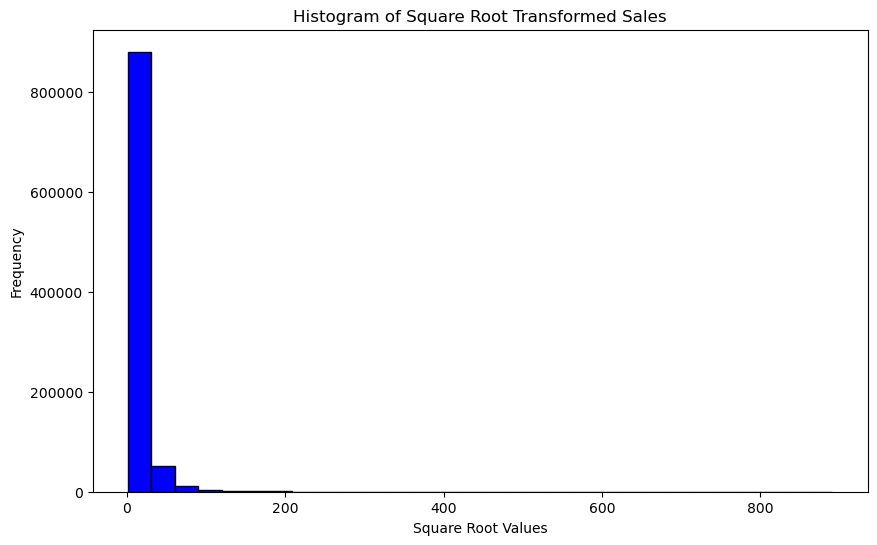

In [751]:
# Applying square root transformation to fix skewness
df['sales_sqrt'] = np.sqrt(df['sales'])

#Displaying histogram after square root transformation
plt.figure(figsize=(10, 6))
plt.hist(df['sales_sqrt'], bins=30, color='blue', edgecolor='black')
plt.title('Histogram of Square Root Transformed Sales')
plt.xlabel('Square Root Values')
plt.ylabel('Frequency')
plt.show()

In [753]:
#calculate skewness after square root transformation
skewness_sqrt = df['sales_sqrt'].skew()
skewness_sqrt


6.712266368145449

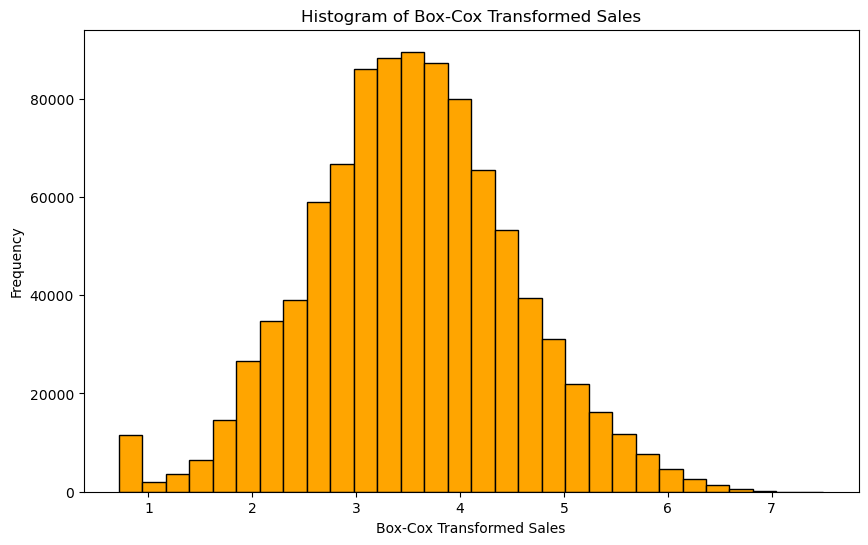

In [761]:
from scipy import stats


#Applying box-cox transformation to fix skewness

df['sales_boxcox'], _ = stats.boxcox(df['sales'] + 1)  # store in DataFrame column

# Displaying histogram after Box-Cox transformation
plt.figure(figsize=(10, 6))
plt.hist(df['sales_boxcox'], bins=30, color='orange', edgecolor='black')
plt.title('Histogram of Box-Cox Transformed Sales')
plt.xlabel('Box-Cox Transformed Sales')
plt.ylabel('Frequency')
plt.show()


In [763]:
#calculate skew after box-cox transformation
skewness_boxcox = df['sales_boxcox'].skew()
skewness_boxcox


-0.009644748590741534

In [ ]:
##finding outliers

In [767]:
# since we have to find outliers per category we used loop through each item_type category


for item in df['item_type'].unique():
    subset = df[df['item_type'] == item]['sales']
    
    print(f"--- Item Type {item} ---")
    
    # Calculate 25th percentile
    percentile25 = subset.quantile(0.25)
    print('Percentile 25:', percentile25)
    
    # Calculate 75th percentile
    percentile75 = subset.quantile(0.75)
    print('Percentile 75:', percentile75)
    
    # Calculate interquartile range (IQR)
    iqr = percentile75 - percentile25
    print('IQR:', iqr)
    
    # Calculate upper and lower thresholds for outliers
    lower_limit = percentile25 - 1.5 * iqr
    upper_limit = percentile75 + 1.5 * iqr
    print('Lower limit:', lower_limit)
    print('Upper limit:', upper_limit)
    
    # Isolate lower-end outliers
    lower_outliers = subset[subset < lower_limit]
    print('Number of lower-end outliers:', len(lower_outliers))
    
    # Isolate upper-end outliers
    upper_outliers = subset[subset > upper_limit]
    print('Number of upper-end outliers:', len(upper_outliers))
    
    print("\n")  # Blank line for readability


--- Item Type 5.0 ---
Percentile 25: 29.240000000000002
Percentile 75: 175.1
IQR: 145.85999999999999
Lower limit: -189.54999999999995
Upper limit: 393.89
Number of lower-end outliers: 0
Number of upper-end outliers: 24493


--- Item Type 7.0 ---
Percentile 25: 22.1
Percentile 75: 145.4
IQR: 123.30000000000001
Lower limit: -162.85000000000002
Upper limit: 330.35
Number of lower-end outliers: 0
Number of upper-end outliers: 53819


--- Item Type 6.0 ---
Percentile 25: 36.6
Percentile 75: 241.1
IQR: 204.5
Lower limit: -270.15
Upper limit: 547.85
Number of lower-end outliers: 0
Number of upper-end outliers: 16879


--- Item Type 1.0 ---
Percentile 25: 182.81
Percentile 75: 1721.1
IQR: 1538.29
Lower limit: -2124.625
Upper limit: 4028.535
Number of lower-end outliers: 0
Number of upper-end outliers: 9789


--- Item Type 4.0 ---
Percentile 25: 27.900000000000002
Percentile 75: 251.1
IQR: 223.2
Lower limit: -306.9
Upper limit: 585.9
Number of lower-end outliers: 0
Number of upper-end outliers:

In [796]:
# --- Calculate and display median sales per item_type ---

# Item Type 1
median_1 = df[df['item_type'] == 1]['sales'].median()
print(f"Item Type 1.0: Median Sales = {median_1}")

# Item Type 2
median_2 = df[df['item_type'] == 2]['sales'].median()
print(f"Item Type 2.0: Median Sales = {median_2}")

# Item Type 3
median_3 = df[df['item_type'] == 3]['sales'].median()
print(f"Item Type 3.0: Median Sales = {median_3}")

# Item Type 4
median_4 = df[df['item_type'] == 4]['sales'].median()
print(f"Item Type 4.0: Median Sales = {median_4}")

# Item Type 5
median_5 = df[df['item_type'] == 5]['sales'].median()
print(f"Item Type 5.0: Median Sales = {median_5}")

# Item Type 6
median_6 = df[df['item_type'] == 6]['sales'].median()
print(f"Item Type 6.0: Median Sales = {median_6}")

# Item Type 7
median_7 = df[df['item_type'] == 7]['sales'].median()
print(f"Item Type 7.0: Median Sales = {median_7}")

# Item Type 8
median_8 = df[df['item_type'] == 8]['sales'].median()
print(f"Item Type 8.0: Median Sales = {median_8}")

# Item Type 9
median_9 = df[df['item_type'] == 9]['sales'].median()
print(f"Item Type 9.0: Median Sales = {median_9}")


Item Type 1.0: Median Sales = 525.85
Item Type 2.0: Median Sales = 223.13625
Item Type 3.0: Median Sales = 55.49
Item Type 4.0: Median Sales = 83.89999999999999
Item Type 5.0: Median Sales = 71.1
Item Type 6.0: Median Sales = 86.3
Item Type 7.0: Median Sales = 53.46
Item Type 8.0: Median Sales = 96.99499999999999
Item Type 9.0: Median Sales = 105.89999999999999


In [792]:
# Replace upper-end outliers per item_type with median 

# Item Type 1
subset_1 = df[df['item_type'] == 1]['sales']
median_1 = subset_1.median()
upper_1 = 4028.535  # already calculated
df.loc[(df['item_type'] == 1) & (df['sales'] > upper_1), 'sales'] = median_1

# Item Type 2
subset_2 = df[df['item_type'] == 2]['sales']
median_2 = subset_2.median()
upper_2 = 1648.175
df.loc[(df['item_type'] == 2) & (df['sales'] > upper_2), 'sales'] = median_2

# Item Type 3
subset_3 = df[df['item_type'] == 3]['sales']
median_3 = subset_3.median()
upper_3 = 452.625
df.loc[(df['item_type'] == 3) & (df['sales'] > upper_3), 'sales'] = median_3

# Item Type 4
subset_4 = df[df['item_type'] == 4]['sales']
median_4 = subset_4.median()
upper_4 = 585.9
df.loc[(df['item_type'] == 4) & (df['sales'] > upper_4), 'sales'] = median_4

# Item Type 5
subset_5 = df[df['item_type'] == 5]['sales']
median_5 = subset_5.median()
upper_5 = 393.89
df.loc[(df['item_type'] == 5) & (df['sales'] > upper_5), 'sales'] = median_5

# Item Type 6
subset_6 = df[df['item_type'] == 6]['sales']
median_6 = subset_6.median()
upper_6 = 547.85
df.loc[(df['item_type'] == 6) & (df['sales'] > upper_6), 'sales'] = median_6

# Item Type 7
subset_7 = df[df['item_type'] == 7]['sales']
median_7 = subset_7.median()
upper_7 = 330.35
df.loc[(df['item_type'] == 7) & (df['sales'] > upper_7), 'sales'] = median_7

# Item Type 8
subset_8 = df[df['item_type'] == 8]['sales']
median_8 = subset_8.median()
upper_8 = 734.85
df.loc[(df['item_type'] == 8) & (df['sales'] > upper_8), 'sales'] = median_8

# Item Type 9
subset_9 = df[df['item_type'] == 9]['sales']
median_9 = subset_9.median()
upper_9 = 381.82
df.loc[(df['item_type'] == 9) & (df['sales'] > upper_9), 'sales'] = median_9



In [794]:
#checking if outliers have been replaced

# --- Item Type 1 ---
df[(df['item_type'] == 1) & (df['sales'] > upper_1)]

# --- Item Type 2 ---
df[(df['item_type'] == 2) & (df['sales'] > upper_2)]

# --- Item Type 3 ---
df[(df['item_type'] == 3) & (df['sales'] > upper_3)]

# --- Item Type 4 ---
df[(df['item_type'] == 4) & (df['sales'] > upper_4)]

# --- Item Type 5 ---
df[(df['item_type'] == 5) & (df['sales'] > upper_5)]

# --- Item Type 6 ---
df[(df['item_type'] == 6) & (df['sales'] > upper_6)]

# --- Item Type 7 ---
df[(df['item_type'] == 7) & (df['sales'] > upper_7)]

# --- Item Type 8 ---
df[(df['item_type'] == 8) & (df['sales'] > upper_8)]

# --- Item Type 9 ---
df[(df['item_type'] == 9) & (df['sales'] > upper_9)]


,customer_district_code,item_type,item_type_description,sales,business_chain_l1_name,business_chain_l1_code,business_area_code,light_source,sales_log,sales_sqrt,sales_boxcox


# Answer to Section 3: Analysis (10 Marks) - do not add any extra cells

## Visualisation 1 (all the codes in one cell) 

C:\Users\bienk\AppData\Local\Temp\ipykernel_26704\3975998423.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='item_type', data=df, palette='Set2')


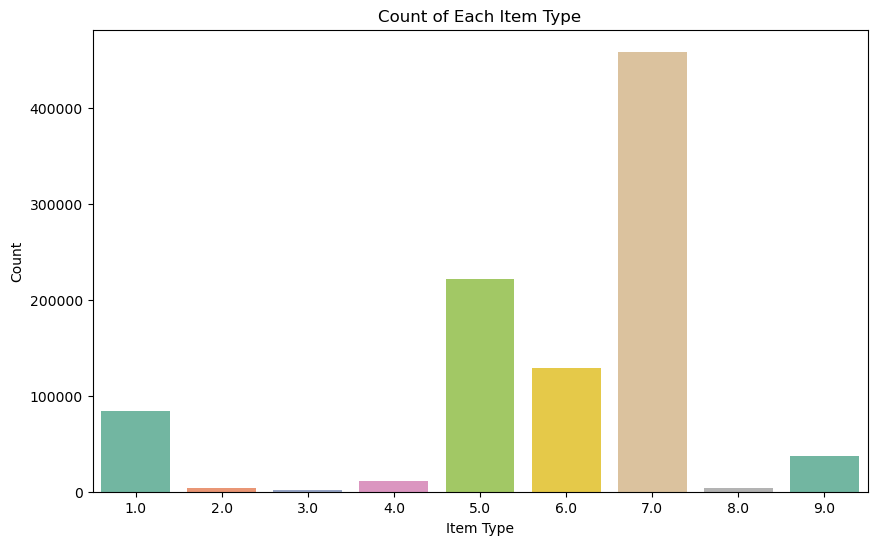

In [798]:
# to create a bar 
# bar chart - The bar chart (countplot) displays the frequency of sales for each item type. 
#This gives insight into which product categories are most popular and which are less in demand among customers.
plt.figure(figsize=(10,6))
sns.countplot(x='item_type', data=df, palette='Set2')
plt.title('Count of Each Item Type')
plt.xlabel('Item Type')
plt.ylabel('Count')
plt.show()


## Visualisation 2 (all the codes in one cell)

C:\Users\bienk\AppData\Local\Temp\ipykernel_26704\3425484370.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='item_type', y='sales', data=df, palette='Set3')


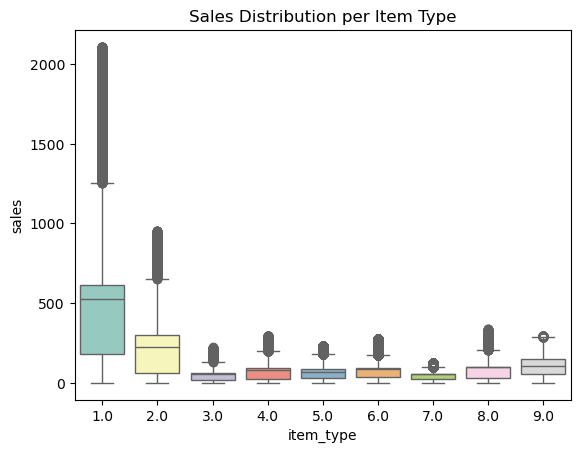

In [800]:
#Boxplot of Sales by Item Type
#The boxplot visualises the spread of sales within each product category and highlights potential outliers. 
#It provides a clear comparison of central tendency and variation across different item types.
sns.boxplot(x='item_type', y='sales', data=df, palette='Set3')
plt.title('Sales Distribution per Item Type')
plt.show()


## Visualisation 3 (all the codes in one cell) 

C:\Users\bienk\AppData\Local\Temp\ipykernel_26704\3833518820.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='business_chain_l1_name', y='sales', data=df[df['business_chain_l1_name'].isin(top_chains)], palette='Paired')


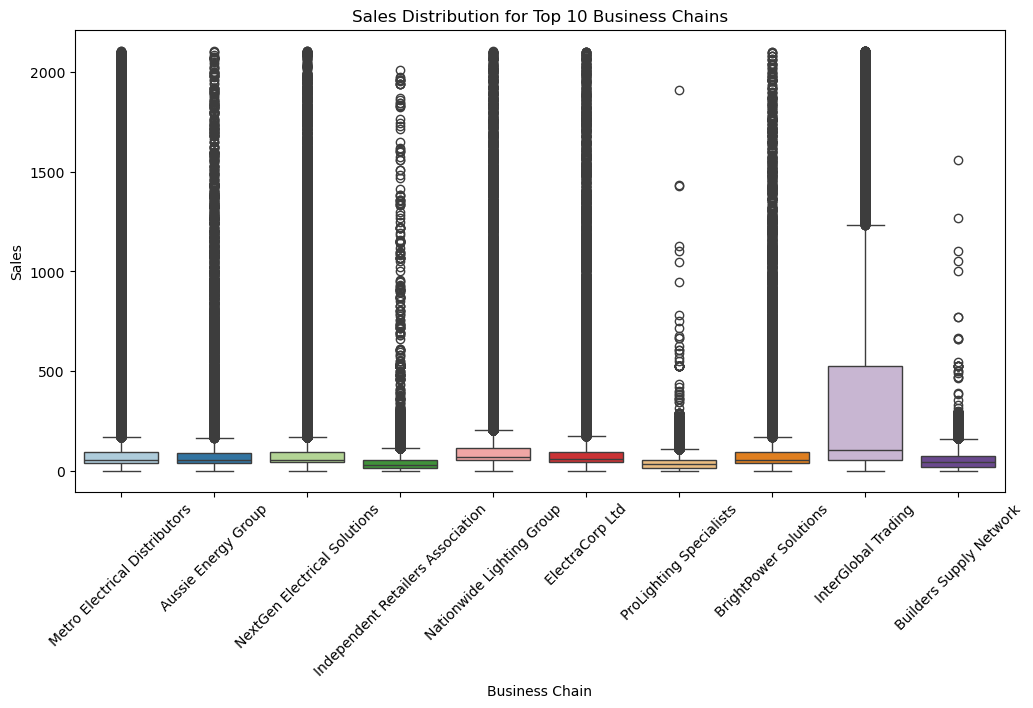

In [802]:
#Scatter Plot
#The scatter plot shows the relationship between sales and another variable (such as business area or district). T
#This helps identify trends, clusters, or unusual sales behaviour across different regions.
top_chains = df['business_chain_l1_name'].value_counts().nlargest(10).index
plt.figure(figsize=(12,6))
sns.boxplot(x='business_chain_l1_name', y='sales', data=df[df['business_chain_l1_name'].isin(top_chains)], palette='Paired')
plt.title('Sales Distribution for Top 10 Business Chains')
plt.xlabel('Business Chain')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.show()


## Visualisation 4 (all the codes in one cell) 

C:\Users\bienk\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


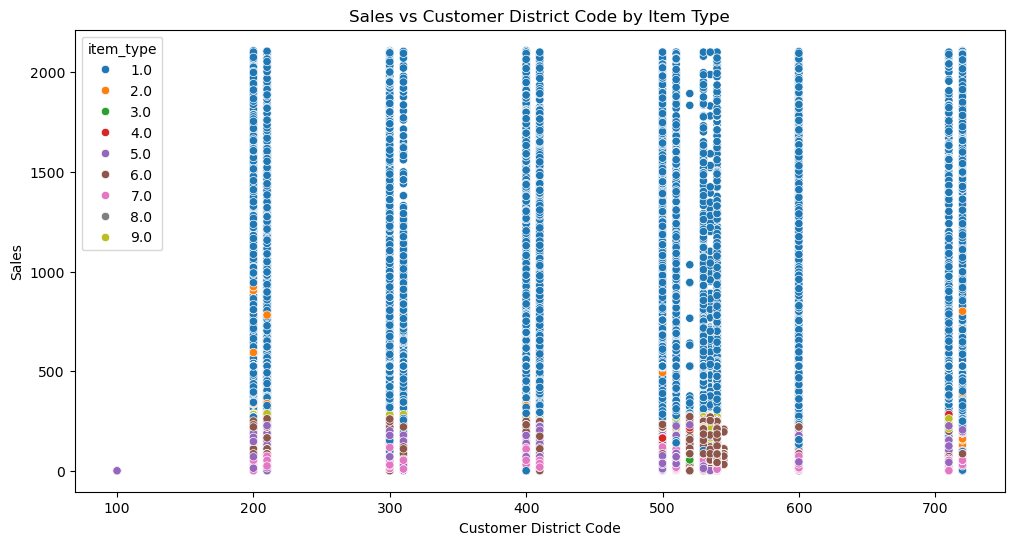

In [804]:
#Scatter plot: Sales vs Customer District Code by item type
#The scatter plot illustrates the relationship between sales values and customer district codes, with points colored by item type. 
#Each dot represents a sales transaction.

This visualization helps identify which districts contribute higher or lower sales, and whether sales patterns differ across item types.
plt.figure(figsize=(12,6))
sns.scatterplot(x='customer_district_code', y='sales', hue='item_type', data=df, palette='tab10')
plt.title('Sales vs Customer District Code by Item Type')
plt.xlabel('Customer District Code')
plt.ylabel('Sales')
plt.show()


## Visualisation 5 (all the codes in one cell) 

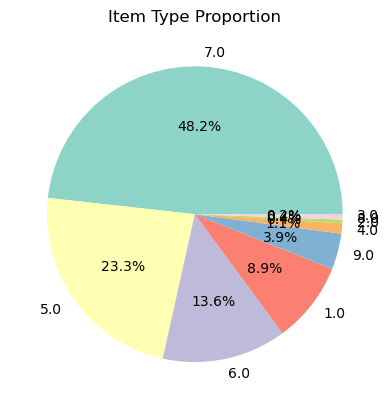

In [806]:
#Pie chart
#he pie chart shows the proportion of total sales contributed by each item type. 
#This helps us understand the relative market share of different lighting products. 
#Larger slices indicate item types with higher sales volumes, while smaller slices represent products with lower demand.

df['item_type'].value_counts().plot.pie(autopct='%1.1f%%', colors=sns.color_palette('Set3'))
plt.title('Item Type Proportion')
plt.ylabel('')
plt.show()


In [814]:

df.to_csv('Assessment 01.xlsx', index=False)
